# GDP per Capita vs. Life Expectancy (Gapminder, 1952–2007)

Exploratory analysis and visualisation of the [Gapminder](https://www.gapminder.org/) dataset
(142 countries, 12 observations each, every 5 years from 1952 to 2007).

**Sections**
1. Trends over time by continent
2. Biggest winners and losers: GDP per capita and life expectancy
3. Distributions in 2007 per continent (box plots + interactive stacked area charts)
4. GDP vs. life expectancy (1952 vs. 2007)
5. Historical anomalies (wars, genocide, ...)
6. Development paths of selected countries
7. Shifting global share of GDP and population
8. Inequality within continents

**Libraries:** Pandas, NumPy, Matplotlib, Seaborn, Plotly Express

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Style settings for static charts
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.autolayout': True})

df = pd.read_csv('../../data/gapminder.csv')
print(df.shape)
df.head()

(1704, 6)


       country continent  year  lifeExp       pop   gdpPercap
0  Afghanistan      Asia  1952   28.801   8425333  779.445314
1  Afghanistan      Asia  1957   30.332   9240934  820.853030
2  Afghanistan      Asia  1962   31.997  10267083  853.100710
3  Afghanistan      Asia  1967   34.020  11537966  836.197138
4  Afghanistan      Asia  1972   36.088  13079460  739.981106

## 1. Trends over time by continent

Average GDP per capita and life expectancy per continent (simple mean over countries, not population-weighted).

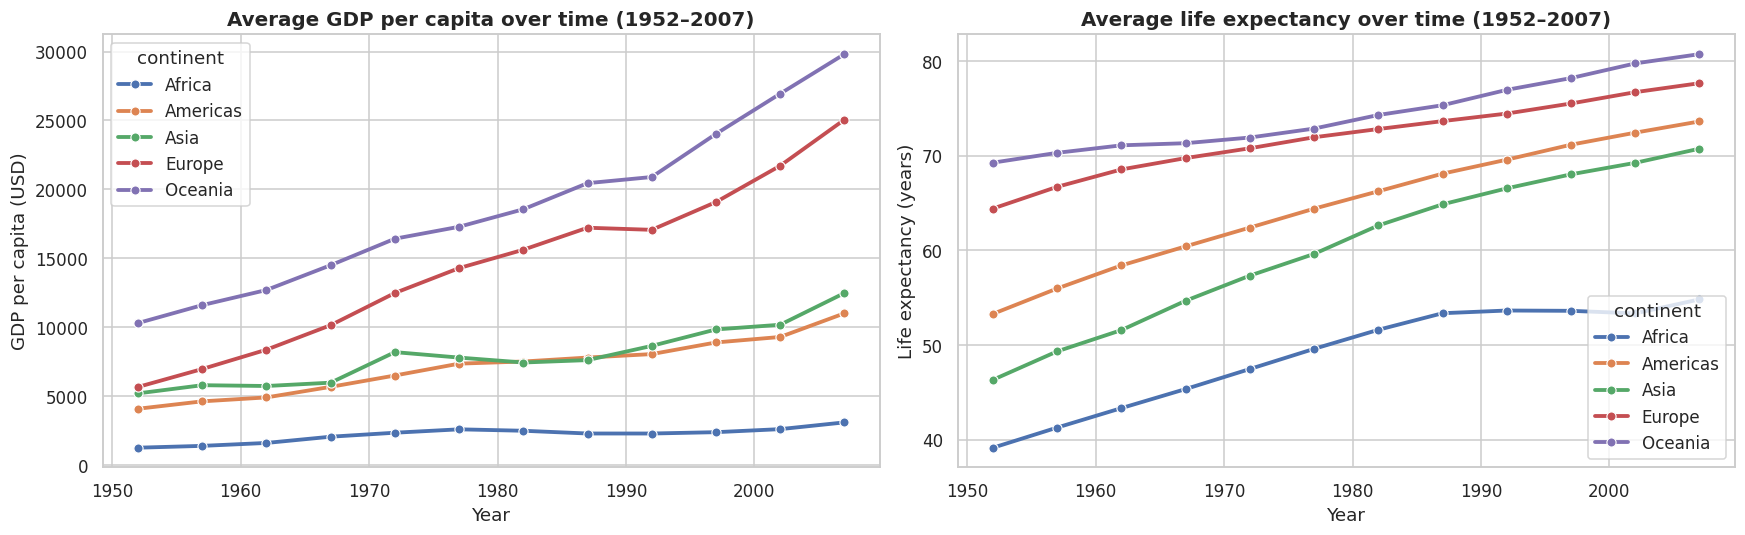

In [2]:
# Aggregate data by continent and year
cont_trends = df.groupby(['continent', 'year'])[['gdpPercap', 'lifeExp']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: change in GDP per capita over time
sns.lineplot(data=cont_trends, x='year', y='gdpPercap', hue='continent', marker='o', linewidth=2.5, ax=axes[0])
axes[0].set_title('Average GDP per capita over time (1952–2007)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('GDP per capita (USD)')

# Plot 2: change in life expectancy over time
sns.lineplot(data=cont_trends, x='year', y='lifeExp', hue='continent', marker='o', linewidth=2.5, ax=axes[1])
axes[1].set_title('Average life expectancy over time (1952–2007)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Life expectancy (years)')

plt.show()

## 2. Biggest winners and losers (1952 → 2007)

### GDP per capita: top 10 increases vs. top 10 smallest increases / declines

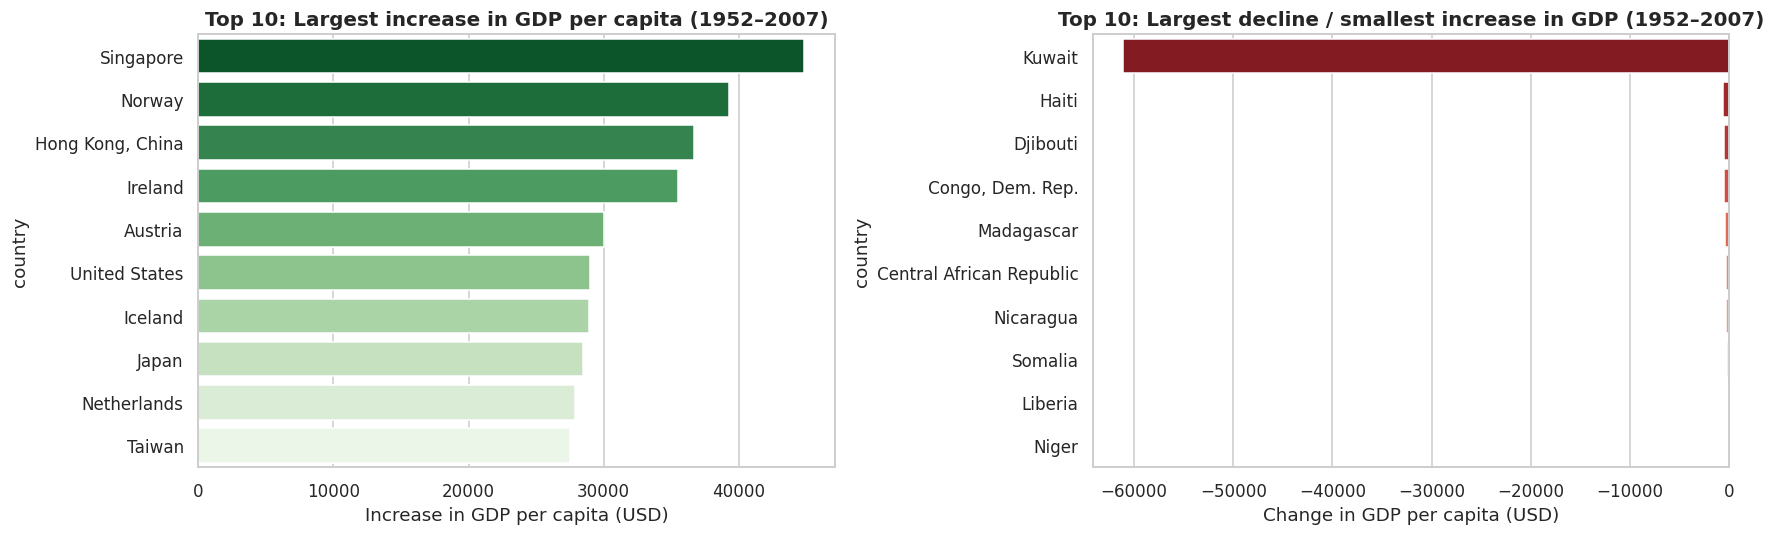

In [3]:
piv_gdp = df.pivot(index='country', columns='year', values='gdpPercap')
gdp_diff = (piv_gdp[2007] - piv_gdp[1952]).reset_index()
gdp_diff.columns = ['country', 'gdp_change']

top10_gdp_growth = gdp_diff.sort_values(by='gdp_change', ascending=False).head(10)
top10_gdp_decline = gdp_diff.sort_values(by='gdp_change', ascending=True).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: top 10 largest GDP increases
sns.barplot(data=top10_gdp_growth, x='gdp_change', y='country', hue='country', palette='Greens_r', legend=False, ax=axes[0])
axes[0].set_title('Top 10: Largest increase in GDP per capita (1952–2007)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Increase in GDP per capita (USD)')

# Plot 2: top 10 smallest increases / largest declines
sns.barplot(data=top10_gdp_decline, x='gdp_change', y='country', hue='country', palette='Reds_r', legend=False, ax=axes[1])
axes[1].set_title('Top 10: Largest decline / smallest increase in GDP (1952–2007)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Change in GDP per capita (USD)')

plt.show()

### Life expectancy: top 10 increases vs. top 10 smallest increases / declines

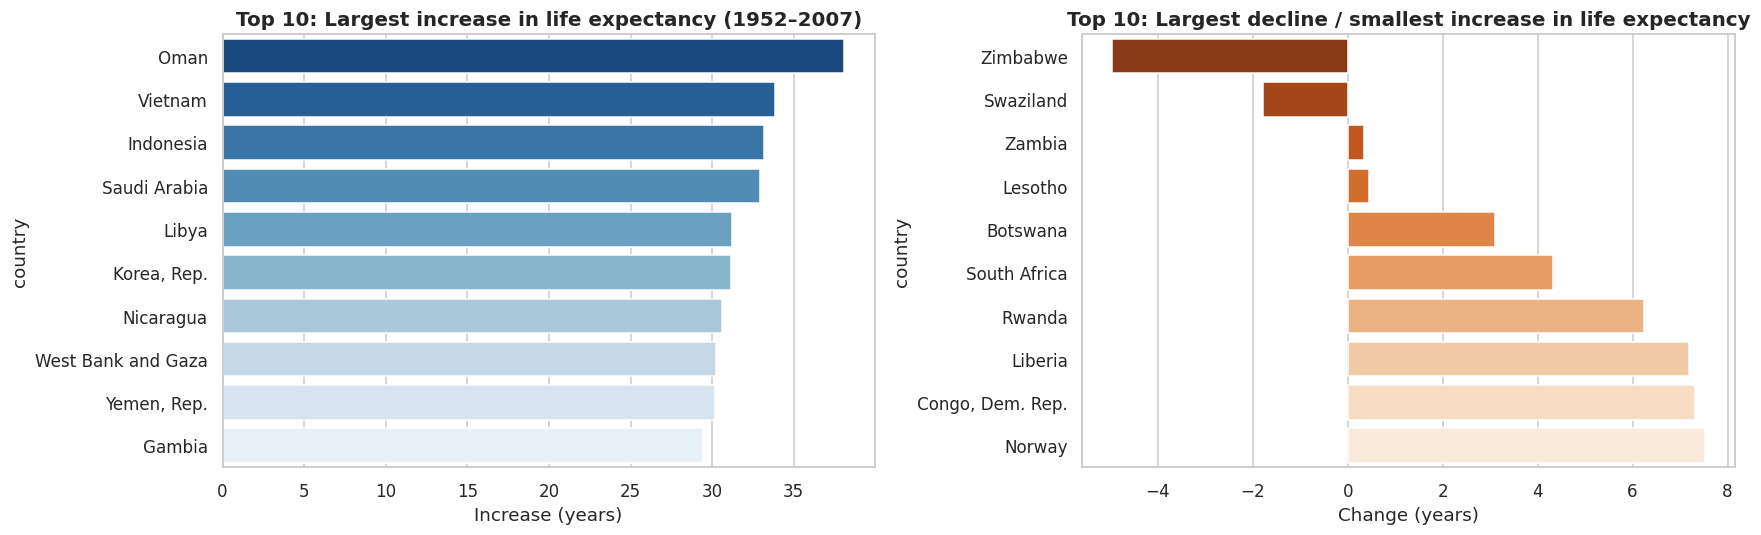

In [4]:
piv_life = df.pivot(index='country', columns='year', values='lifeExp')
life_diff = (piv_life[2007] - piv_life[1952]).reset_index()
life_diff.columns = ['country', 'life_change']

top10_life_growth = life_diff.sort_values(by='life_change', ascending=False).head(10)
top10_life_decline = life_diff.sort_values(by='life_change', ascending=True).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: top 10 largest increases in life expectancy
sns.barplot(data=top10_life_growth, x='life_change', y='country', hue='country', palette='Blues_r', legend=False, ax=axes[0])
axes[0].set_title('Top 10: Largest increase in life expectancy (1952–2007)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Increase (years)')

# Plot 2: top 10 largest declines / smallest increases
sns.barplot(data=top10_life_decline, x='life_change', y='country', hue='country', palette='Oranges_r', legend=False, ax=axes[1])
axes[1].set_title('Top 10: Largest decline / smallest increase in life expectancy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Change (years)')

plt.show()

## 3. Distributions in 2007 per continent

### GDP per capita: box plot (log scale) and interactive stacked area chart

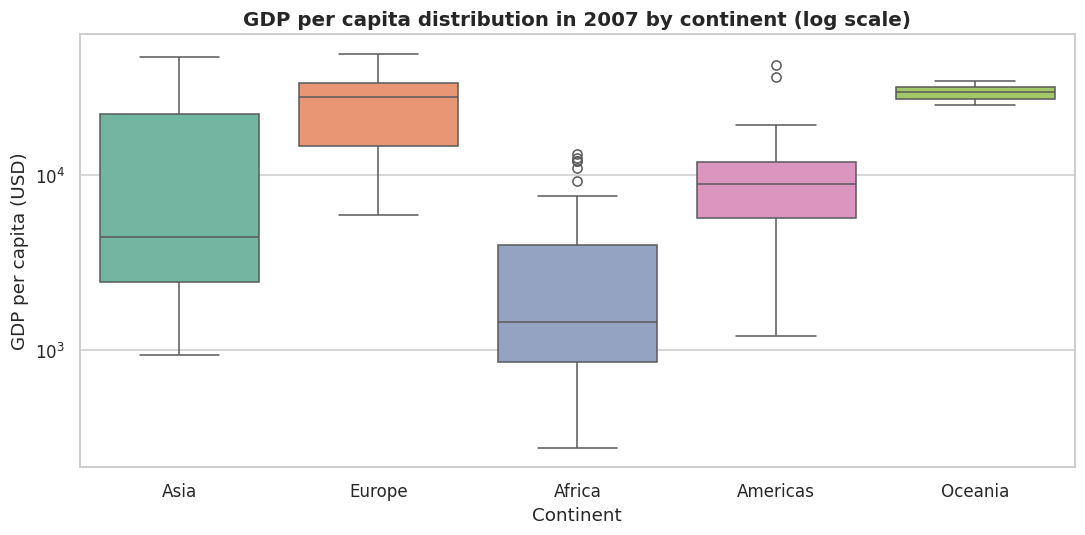

In [5]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[df['year'] == 2007], x='continent', y='gdpPercap', hue='continent', palette='Set2', legend=False)
plt.yscale('log')  # log scale because the data is heavily skewed
plt.title('GDP per capita distribution in 2007 by continent (log scale)', fontsize=13, fontweight='bold')
plt.xlabel('Continent')
plt.ylabel('GDP per capita (USD)')
plt.show()

In [ ]:
# Interactive stacked area chart (Plotly): GDP per capita per country, one panel per continent
fig_gdp_stacked = px.area(
    df,
    x="year",
    y="gdpPercap",
    color="country",
    facet_col="continent",
    facet_col_wrap=3,
    title="Interactive Stacked Area Chart: GDP per capita of countries within each continent"
)
fig_gdp_stacked.update_layout(showlegend=False, height=700)
fig_gdp_stacked.show()

### Life expectancy: box plot and interactive stacked area chart

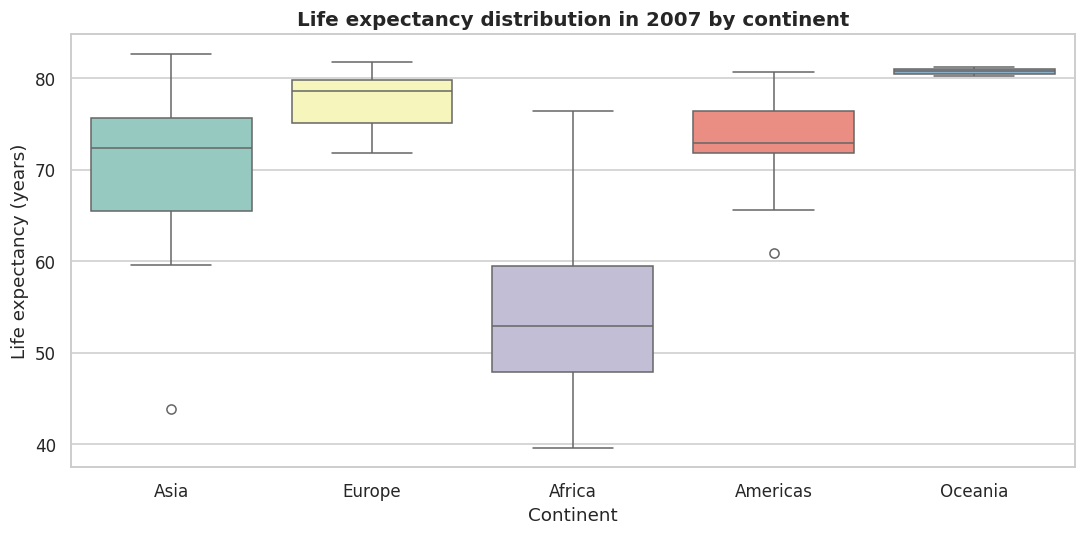

In [6]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[df['year'] == 2007], x='continent', y='lifeExp', hue='continent', palette='Set3', legend=False)
plt.title('Life expectancy distribution in 2007 by continent', fontsize=13, fontweight='bold')
plt.xlabel('Continent')
plt.ylabel('Life expectancy (years)')
plt.show()

In [ ]:
# Interactive stacked area chart (Plotly): life expectancy per country, one panel per continent
fig_life_stacked = px.area(
    df,
    x="year",
    y="lifeExp",
    color="country",
    facet_col="continent",
    facet_col_wrap=3,
    title="Interactive Stacked Area Chart: life expectancy of countries within each continent"
)
fig_life_stacked.update_layout(showlegend=False, height=700)
fig_life_stacked.show()

## 4. GDP vs. life expectancy: 1952 vs. 2007

Bubble size = population, log-scaled x-axis.

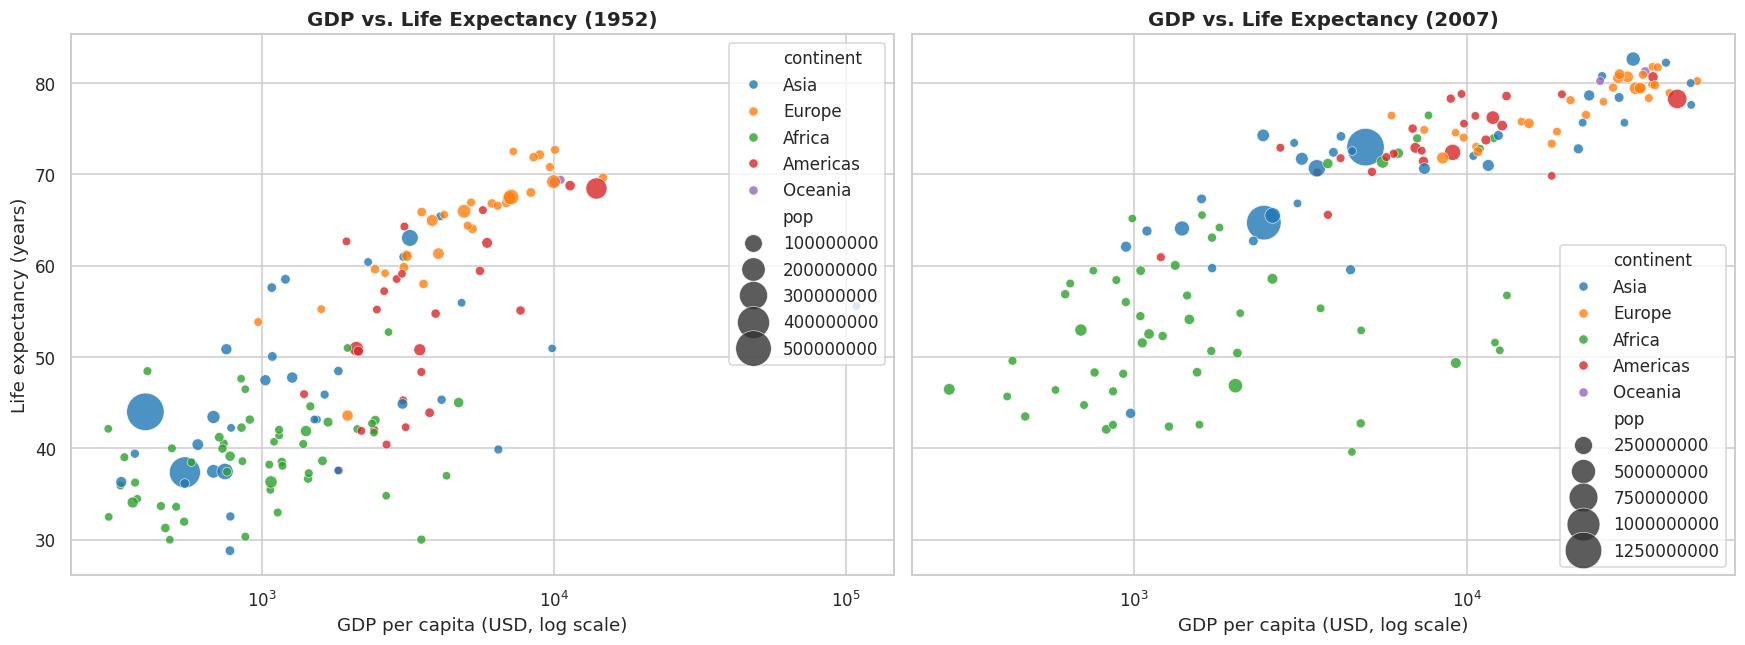

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Correlation 1: GDP vs. life expectancy in 1952
sub_1952 = df[df['year'] == 1952]
sns.scatterplot(
    data=sub_1952, x='gdpPercap', y='lifeExp', hue='continent', size='pop',
    sizes=(30, 600), palette='tab10', alpha=0.8, ax=axes[0]
)
axes[0].set_xscale('log')
axes[0].set_title('GDP vs. Life Expectancy (1952)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('GDP per capita (USD, log scale)')
axes[0].set_ylabel('Life expectancy (years)')

# Correlation 2: GDP vs. life expectancy in 2007
sub_2007 = df[df['year'] == 2007]
sns.scatterplot(
    data=sub_2007, x='gdpPercap', y='lifeExp', hue='continent', size='pop',
    sizes=(30, 600), palette='tab10', alpha=0.8, ax=axes[1]
)
axes[1].set_xscale('log')
axes[1].set_title('GDP vs. Life Expectancy (2007)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('GDP per capita (USD, log scale)')

plt.show()

## 5. Historical anomalies

Countries with the most dramatic swings in the data. What caused them? Possible explanations include wars, the break-up of states and genocides.

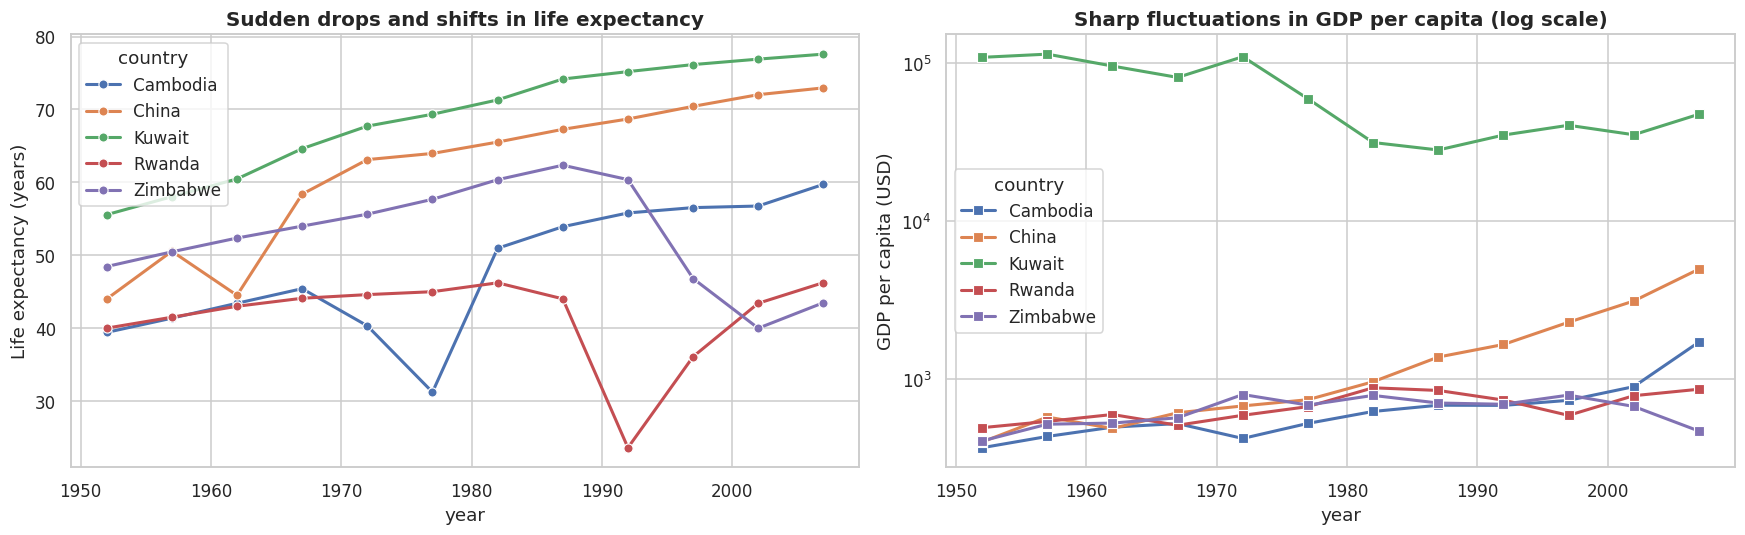

In [8]:
anomaly_countries = ['Rwanda', 'Zimbabwe', 'Kuwait', 'China', 'Cambodia']
df_anomalies = df[df['country'].isin(anomaly_countries)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Life expectancy trajectory of the anomalous countries
sns.lineplot(data=df_anomalies, x='year', y='lifeExp', hue='country', marker='o', linewidth=2, ax=axes[0])
axes[0].set_title('Sudden drops and shifts in life expectancy', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Life expectancy (years)')

# GDP per capita trajectory of the anomalous countries
sns.lineplot(data=df_anomalies, x='year', y='gdpPercap', hue='country', marker='s', linewidth=2, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Sharp fluctuations in GDP per capita (log scale)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('GDP per capita (USD)')

plt.show()

## 6. Development paths of selected countries (1952 → 2007)

Each line connects a country's (GDP, life expectancy) positions over time. Labels `52` and `07` mark the start and end points.

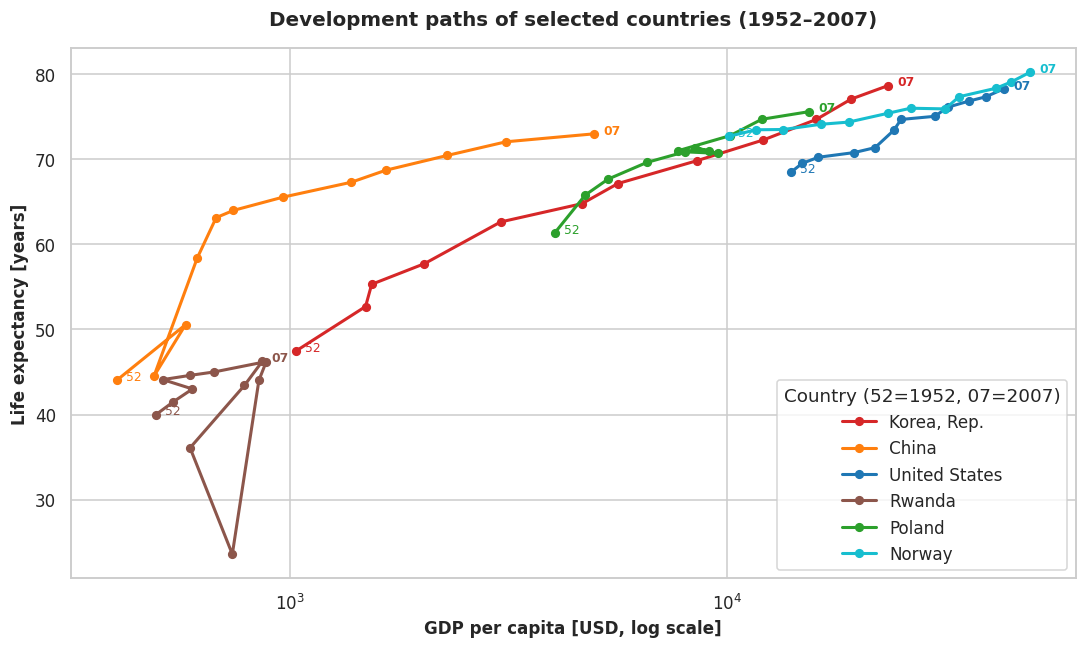

In [9]:
plt.figure(figsize=(10, 6), dpi=150)
selected_countries = ['Korea, Rep.', 'China', 'United States', 'Rwanda', 'Poland', 'Norway']
colors_country = {
    'Korea, Rep.': '#d62728',
    'China': '#ff7f0e',
    'United States': '#1f77b4',
    'Rwanda': '#8c564b',
    'Poland': '#2ca02c',
    'Norway': '#17becf',
}

for country in selected_countries:
    c_df = df[df['country'] == country].sort_values('year')
    plt.plot(
        c_df['gdpPercap'],
        c_df['lifeExp'],
        marker='o',
        color=colors_country[country],
        label=country,
        linewidth=2,
        markersize=5,
    )
    plt.text(c_df.iloc[0]['gdpPercap'] * 1.05, c_df.iloc[0]['lifeExp'], '52',
             fontsize=8, color=colors_country[country])
    plt.text(c_df.iloc[-1]['gdpPercap'] * 1.05, c_df.iloc[-1]['lifeExp'], '07',
             fontsize=8, fontweight='bold', color=colors_country[country])

plt.xscale('log')
plt.title('Development paths of selected countries (1952–2007)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('GDP per capita [USD, log scale]', fontsize=11, fontweight='bold')
plt.ylabel('Life expectancy [years]', fontsize=11, fontweight='bold')
plt.legend(title='Country (52=1952, 07=2007)', frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

## 7. Shifting global share of GDP and population (1952 vs. 2007)

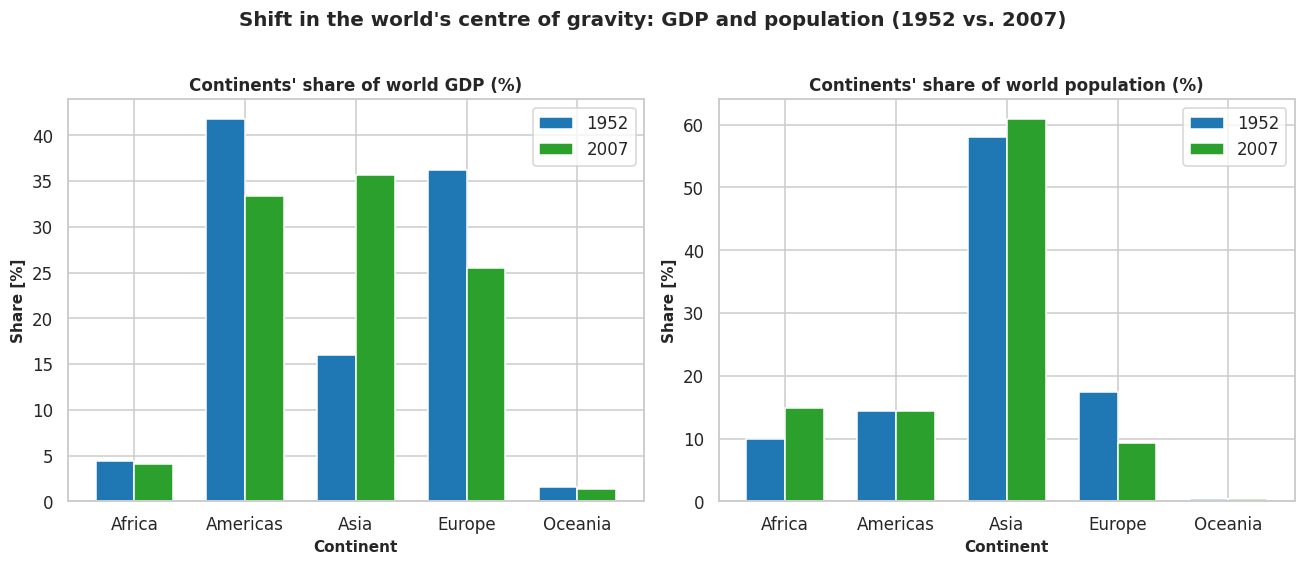

In [10]:
df['totalGdp'] = df['gdpPercap'] * df['pop']

cont_summary = df.groupby(['year', 'continent'])[['pop', 'totalGdp']].sum().reset_index()
s1952 = cont_summary[cont_summary['year'] == 1952].set_index('continent')
s2007 = cont_summary[cont_summary['year'] == 2007].set_index('continent')

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=150)

gdp_comp = pd.DataFrame({
    '1952': s1952['totalGdp'] / s1952['totalGdp'].sum() * 100,
    '2007': s2007['totalGdp'] / s2007['totalGdp'].sum() * 100,
})
gdp_comp.plot(kind='bar', ax=axes[0], color=['#1f77b4', '#2ca02c'], width=0.7)
axes[0].set_title("Continents' share of world GDP (%)", fontsize=11, fontweight='bold')
axes[0].set_ylabel('Share [%]', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Continent', fontsize=10, fontweight='bold')
axes[0].tick_params(axis='x', rotation=0)

pop_comp = pd.DataFrame({
    '1952': s1952['pop'] / s1952['pop'].sum() * 100,
    '2007': s2007['pop'] / s2007['pop'].sum() * 100,
})
pop_comp.plot(kind='bar', ax=axes[1], color=['#1f77b4', '#2ca02c'], width=0.7)
axes[1].set_title("Continents' share of world population (%)", fontsize=11, fontweight='bold')
axes[1].set_ylabel('Share [%]', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Continent', fontsize=10, fontweight='bold')
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle("Shift in the world's centre of gravity: GDP and population (1952 vs. 2007)",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 8. Inequality within continents

Life expectancy distribution per continent in 1952, 1980 and 2007.

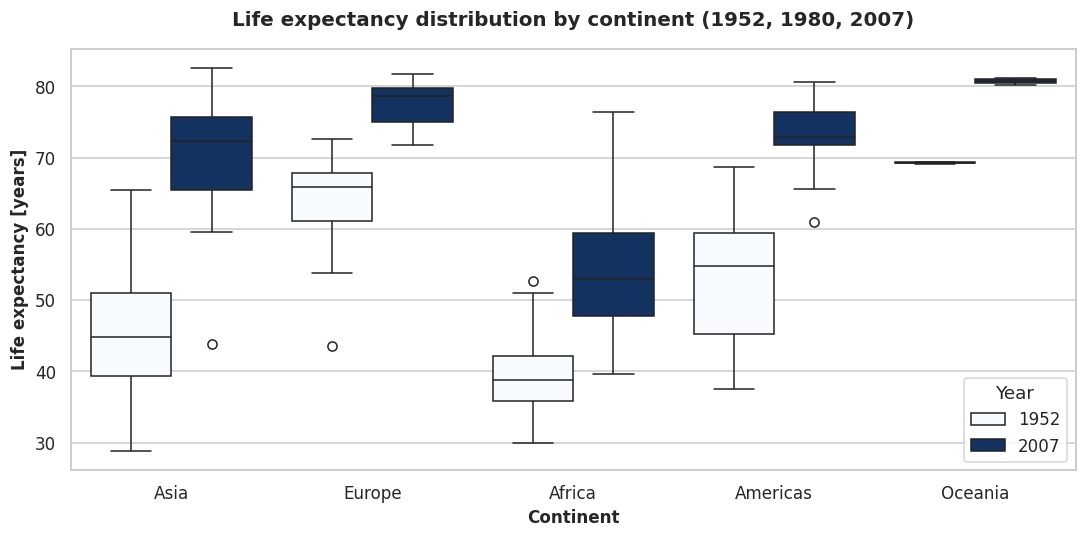

In [11]:
plt.figure(figsize=(10, 5), dpi=150)
sns.boxplot(
    data=df[df['year'].isin([1952, 1980, 2007])],
    x='continent',
    y='lifeExp',
    hue='year',
    palette='Blues',
)
plt.title('Life expectancy distribution by continent (1952, 1980, 2007)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Continent', fontsize=11, fontweight='bold')
plt.ylabel('Life expectancy [years]', fontsize=11, fontweight='bold')
plt.legend(title='Year', frameon=True)
plt.tight_layout()
plt.show()